In [1]:
# https://github.com/magic-telescopes/acme_magic_odas
# https://docs.gammapy.org/1.3/tutorials/analysis-1d/ebl.html

In [2]:
import numpy as np
import astropy.units as u
from pathlib import Path
from astropy.time import Time
from astropy.coordinates import SkyCoord
from regions import PointSkyRegion
import matplotlib.pyplot as plt
import logging
import warnings

from gammapy.maps import MapAxis, RegionGeom
from gammapy.data import DataStore
from gammapy.datasets import SpectrumDataset, Datasets
from gammapy.makers import (
    SpectrumDatasetMaker,
    WobbleRegionsFinder,
    ReflectedRegionsBackgroundMaker,
)
from gammapy.modeling.models import (
    PowerLawSpectralModel,
    SkyModel,
    EBL_DATA_BUILTIN,
    EBLAbsorptionNormSpectralModel,
)
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator

logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)

/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
datastore = DataStore.from_dir("../../MAGICDATA/B21420+326_dl3_data/standard_trigger")
observations_all = datastore.get_observations(required_irf=["rad_max", "aeff", "edisp"])

period_c = Time([58868.3, 58870.3], format="mjd", scale="tt")
observations = observations_all.select_time([period_c])

In [4]:
observations_sorted = sorted(
    observations,
    key=lambda obs: np.min(obs.events.time)
)
print(f"Observations: {len(observations)}")

print(f"Start: {observations_sorted[0].tstart.mjd:.4f}")
print(f"Stop:  {observations_sorted[-1].tstop.mjd:.4f}")

Observations: 5
Start: 58869.2236
Stop:  58869.2939


In [5]:
coords = SkyCoord.from_name("OQ 334")

on_region = PointSkyRegion(coords)

energy_axis = MapAxis.from_energy_bounds(
    1, 1e5, nbin=20, per_decade=False, unit="GeV", name="energy"
)
energy_axis_true = MapAxis.from_energy_bounds(
    1, 1e5, nbin=30, per_decade=False, unit="GeV", name="energy_true"
)

geom = RegionGeom.create(region=on_region, axes=[energy_axis])
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

In [6]:
dataset_maker = SpectrumDatasetMaker(
    containment_correction=False, selection=["counts", "exposure", "edisp"]
)

region_finder = WobbleRegionsFinder(n_off_regions=3)
bkg_maker = ReflectedRegionsBackgroundMaker(region_finder=region_finder)

datasets = Datasets()
for observation in observations:
    dataset = dataset_maker.run(
        dataset_empty.copy(name=str(observation.obs_id)), observation
    )
    dataset_on_off = bkg_maker.run(dataset, observation)
    datasets.append(dataset_on_off)

'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' axis is stored as a scalar -- converting to 1D array.
'THETA' 

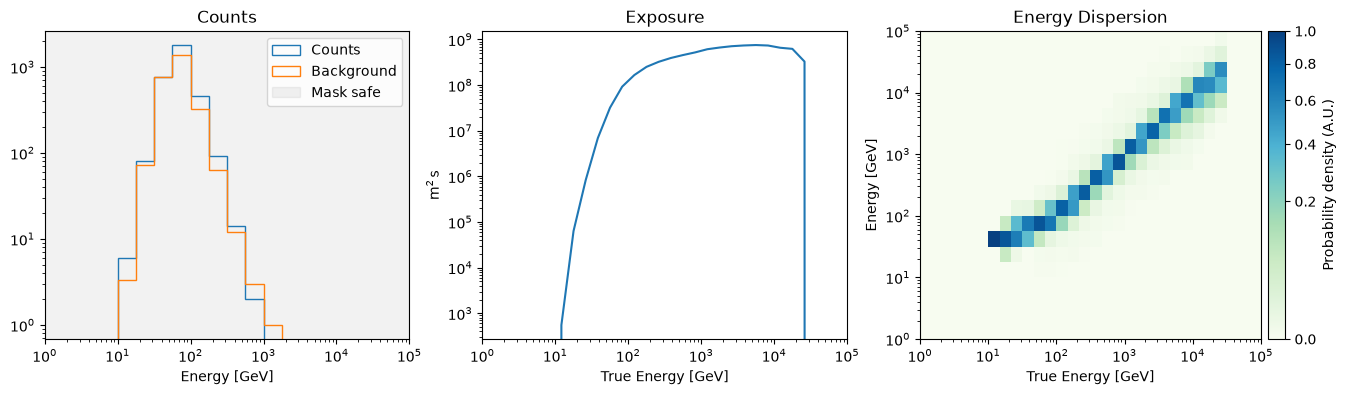

In [7]:
stacked = datasets.stack_reduce(name="OQ334MAGIC")
stacked.peek()

In [8]:
e_min = 50 * u.GeV 
e_max = 500 * u.GeV

stacked.mask_fit = stacked.counts.geom.energy_mask(e_min, e_max)

In [9]:
pwl_model = PowerLawSpectralModel(
    amplitude=5e-12 * u.Unit("TeV-1 cm-2 s-1"),
    reference=0.1 * u.TeV,
    index=2.0 * u.Unit(""),
)

pwl_model.amplitude.min = 1e-20
pwl_model.amplitude.max = 1e-5

redshift = 0.681
absorption = EBLAbsorptionNormSpectralModel.read_builtin("dominguez", redshift=redshift)

spectral_model = pwl_model * absorption
print(spectral_model)

CompoundSpectralModel
    Component 1 : PowerLawSpectralModel

type    name     value         unit      ...    max    frozen link prior
---- --------- ---------- -------------- ... --------- ------ ---- -----
         index 2.0000e+00                ...       nan  False           
     amplitude 5.0000e-12 TeV-1 s-1 cm-2 ... 1.000e-05  False           
     reference 1.0000e-01            TeV ...       nan   True           
    Component 2 : EBLAbsorptionNormSpectralModel

type    name      value    unit   error   min max frozen link prior
---- ---------- ---------- ---- --------- --- --- ------ ---- -----
       redshift 6.8100e-01      0.000e+00 nan nan   True           
     alpha_norm 1.0000e+00      0.000e+00 nan nan   True           
    Operator : mul



In [10]:
model = SkyModel(spectral_model=spectral_model, name="OQ334Model")
stacked.models = [model]

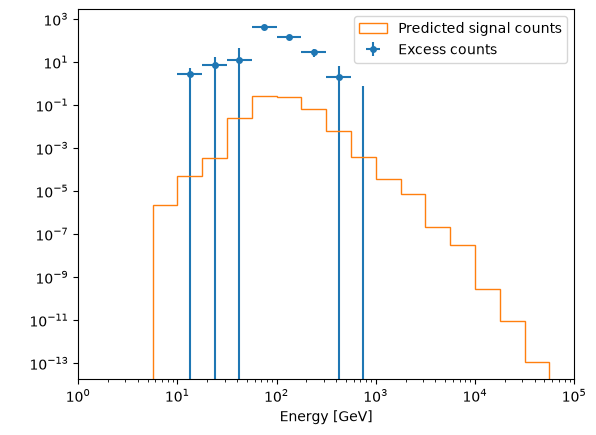

In [11]:
stacked.plot_excess()
plt.show()

In [12]:
fit = Fit()

results = fit.run(datasets=stacked)
print(results)

print(spectral_model)

/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 162
	total stat : 0.95

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.

CompoundSpectralModel
    Component 1 : PowerLawSpectralModel

type    name     value         unit      ...    max    frozen link prior
---- --------- ---------- -------------- ... --------- ------ ---- -----
         index 3.6240e+00                ...       nan  False           
     amplitude 3.7427e-09 TeV-1 s-1 cm-2 ... 1.000e-05  False           
     reference 1.0000e-01            TeV ...       nan   True           
    Component 2 : EBLAbsorptionNormSpectralModel

type    name      value    unit   error   min max frozen link prior
---- ---------- ---------- ---- --------- --- --- ------ ---- -----
       redshift 6.8100e-01      0.000e+00 nan nan   True           
     alpha_norm 1.0000e+00 

In [13]:
model_best = model.copy()

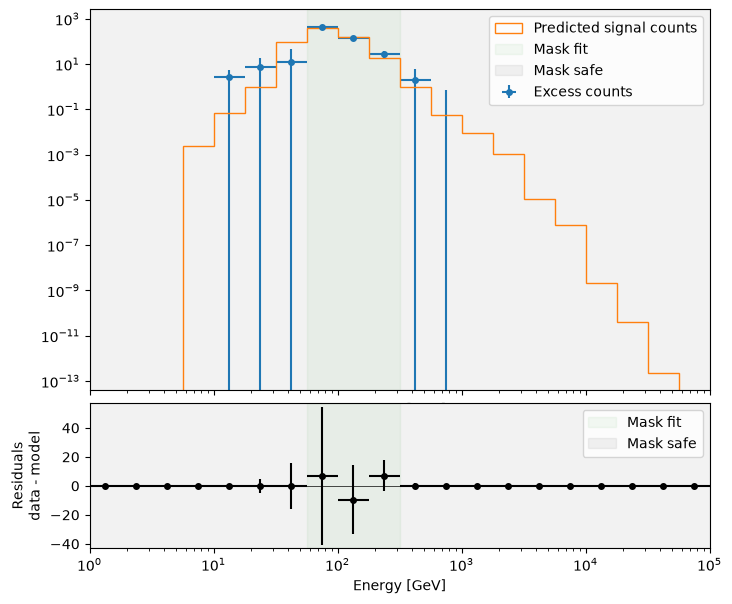

In [14]:
ax_spectrum, ax_residuals = stacked.plot_fit()
plt.show()

In [15]:
energy_edges = stacked.counts.geom.axes["energy"].edges[7:11]

fpe_magic = FluxPointsEstimator(
    energy_edges=energy_edges, 
    source="OQ334Model", 
    selection_optional="all"
)

flux_points_obs = fpe_magic.run(datasets=stacked)

In [16]:
flux_points_intrinsic = flux_points_obs.copy(
    reference_model=SkyModel(spectral_model=pwl_model)
)

print(flux_points_obs.reference_model)
print(flux_points_intrinsic.reference_model)

Changing the reference model will change the fluxes. Handle with care.


SkyModel

  Name                      : g-LyrPa1
  Datasets names            : None
  Spectral model type       : CompoundSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      3.624   +/-    0.32             
    amplitude                     :   3.74e-09   +/- 5.4e-10 1 / (TeV s cm2)
    reference             (frozen):      0.100       TeV         
    redshift              (frozen):      0.681                   
    alpha_norm            (frozen):      1.000                   


SkyModel

  Name                      : t5fleRUG
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      3.624   +/-    0.32             
    amplitude                     :   3.74e-09   +/- 5.4e-10 1 / (TeV s cm2)
    reference             (frozen):      0.100       TeV         




/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(
/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


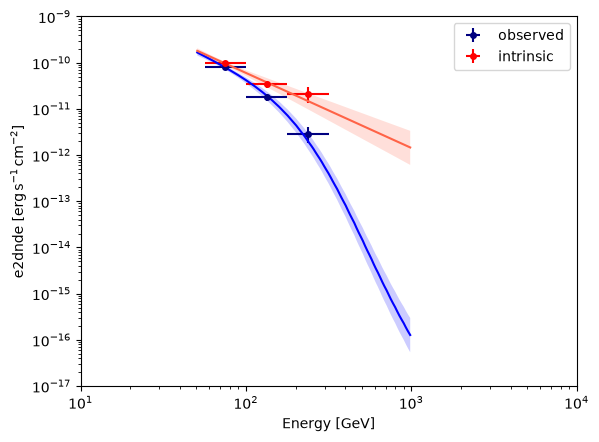

In [17]:
plt.figure()
sed_type = "e2dnde"
energy_bounds = [50, 1e3] * u.GeV

ax = flux_points_obs.plot(sed_type=sed_type, label="observed", color="navy")
flux_points_intrinsic.plot(ax=ax, sed_type=sed_type, label="intrinsic", color="red")

model_best.spectral_model.plot(
    ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="blue"
)
model_best.spectral_model.plot_error(
    ax=ax, energy_bounds=energy_bounds, sed_type="e2dnde", facecolor="blue"
)

pwl_model.plot(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="tomato")
pwl_model.plot_error(
    ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, facecolor="tomato"
)

ax.set_xlim(10, 1e4)
ax.set_ylim(1e-17, 1e-9)
plt.legend()
plt.show()

In [18]:
table_obs = flux_points_obs.to_table(sed_type="e2dnde", formatted=True)
table_obs.write("MAGIC_sed_flux_points_obs_c.fits", overwrite=True)

table_intrinsic = flux_points_intrinsic.to_table(sed_type="e2dnde", formatted=True)
table_intrinsic.write("MAGIC_sed_flux_points_intrinsic_c.fits", overwrite=True)
display(table_intrinsic)

e_ref,e_min,e_max,e2dnde,e2dnde_err,e2dnde_errp,e2dnde_errn,e2dnde_ul,e2dnde_sensitivity,ts,sqrt_ts,npred,npred_excess,stat,stat_null,stat_scan,is_ul,counts,success,norm_scan
GeV,GeV,GeV,erg / (s cm2),erg / (s cm2),erg / (s cm2),erg / (s cm2),erg / (s cm2),erg / (s cm2),,,,,,,,,,,
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64[1],float32[1],float64,float64,float64[11],bool,float64[1],bool,float64[11]
74.989,56.234,100.000,9.766e-11,1.117e-11,1.123e-11,1.112e-11,1.202e-10,4.063e-11,83.479,9.137,1796.9820672817318,415.31076,0.000,83.479,53.053 .. 841.471,False,1797.0,True,0.200 .. 5.000
133.352,100.000,177.828,3.467e-11,5.857e-12,5.920e-12,5.798e-12,4.668e-11,2.526e-11,39.710,6.302,463.8531325571042,141.48576,0.000,39.710,23.752 .. 427.876,False,464.0,True,0.200 .. 5.000
237.137,177.828,316.228,2.133e-11,8.110e-12,8.306e-12,7.926e-12,3.836e-11,4.387e-11,7.818,2.796,91.99957411271421,27.999468,0.000,7.818,5.709 .. 31.538,False,92.0,True,0.200 .. 5.000


/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(
/home/navaneeth/miniconda3/envs/gammapy/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


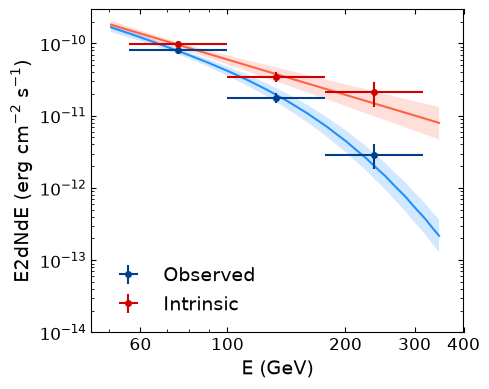

In [19]:
import matplotlib.ticker as mticker

plt.figure(figsize=(5, 4))
sed_type = "e2dnde"
energy_bounds = [50, 350] * u.GeV

ax = flux_points_obs.plot(sed_type=sed_type, label="Observed", color="#023e8a", zorder=3)
flux_points_intrinsic.plot(ax=ax, sed_type=sed_type, label="Intrinsic", color="#d00000", zorder=3)

model_best.spectral_model.plot(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="dodgerblue")
model_best.spectral_model.plot_error(ax=ax, energy_bounds=energy_bounds, sed_type="e2dnde", facecolor="dodgerblue")

pwl_model.plot(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, color="tomato")
pwl_model.plot_error(ax=ax, energy_bounds=energy_bounds, sed_type=sed_type, facecolor="tomato")

ax.set_xlabel(r'E (GeV)', fontsize=14)
ax.set_ylabel(r'E2dNdE (erg cm$^{-2}$ s$^{-1}$)', fontsize=14)
ax.set_xlim(45, 400)
ax.set_ylim(1e-14, 3e-10)

ax.tick_params(axis="both", which="major", labelsize=12, direction="in", top=True, right=True,)
ax.minorticks_on()
ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True,)

ax.set_xticks([60, 100, 200, 300, 400])
ax.xaxis.set_major_formatter(mticker.ScalarFormatter())

plt.legend(fontsize=14, loc="lower left", frameon=False,)
plt.tight_layout()
plt.savefig(f"MAGIC_VHE_SED_C.png", dpi=300)
plt.show()